# Node-Specific Self-Loop Tests with Visual Highlighting



In [1]:
import sys, os, numpy as np, matplotlib.pyplot as plt

# ── Environment detection: Colab vs local ──────────────────────
in_colab = False
try:
    import google.colab
    in_colab = True
except ImportError:
    pass

if in_colab:
    from google.colab import drive
    drive.mount('/content/drive')
    utils_path = '/content/drive/MyDrive/ColabProject/utils'
else:
    # Local: path relative to notebook directory
    utils_path = os.path.join(os.getcwd(), "..", "utils")

sys.path.insert(0, utils_path)

# ── Ensure experiments directory exists ───────────────────────
exp_dir = os.path.join(os.path.dirname(utils_path), "experiments")
os.makedirs(exp_dir, exist_ok=True)

# ── Imports ───────────────────────────────────────────────────
from test_networks import *
from self_loop_utils import *
from laplacian_utils import print_laplacian
from pipeline_utils import run_full_pipeline, run_impedance
from network_visualization import draw_chain_panel, draw_ladder_panel
from network_visualization import draw_self_loop, draw_self_loop_ladder
from experiment_manager import setup_experiment
from impedance_calculator import ImpedanceCalculator, merge_boundary_nodes

print("All modules imported.")

Mounted at /content/drive
All modules imported.


## Enhanced Drawing Functions with Node Highlighting


In [2]:
def draw_chain_panel_hl(ax, intersections, segment_to_nodes, voltages,
                         source_node, drain_node, title,
                         node_labels=None, y_mid=0.50,
                         highlight_nodes=None):
    """
    Draw a horizontal‑chain network with nodes coloured by voltage.
    Nodes listed in `highlight_nodes` get a thick orange border.

    Parameters
    ----------
    highlight_nodes : list of int or None
        Node indices to highlight (self-loop hosts).  Default: no highlights.
    """
    if highlight_nodes is None:
        highlight_nodes = []

    nx = [p[0] for p in intersections]
    ny = [y_mid] * len(intersections)

    ax.set_xlim(-0.08, 1.08)
    ax.set_ylim(0.05, 0.95)
    ax.set_xticks([0.0, 0.5, 1.0])
    ax.set_xticklabels(["0", "0.5", "1"], fontsize=7)
    ax.set_yticks([])
    ax.set_title(title, fontsize=9, pad=3)
    ax.axvline(0.1, ls='--', lw=0.7, color='steelblue', alpha=0.4)
    ax.axvline(0.9, ls='--', lw=0.7, color='tomato', alpha=0.4)

    # Count self-loops per node
    loop_count = {}
    for n1, n2 in segment_to_nodes.values():
        if n1 == n2:
            loop_count[n1] = loop_count.get(n1, 0) + 1

    # Adjust y‑limits to make room for self-loop arcs above the chain
    if loop_count:
        max_loops = max(loop_count.values(), default=0)
        ax.set_ylim(0.05, 0.95 + 0.1 * max_loops)

    # Draw real edges
    for n1, n2 in segment_to_nodes.values():
        if n1 != n2:
            ax.plot([nx[n1], nx[n2]], [y_mid, y_mid], 'k-', lw=2, zorder=2)

    # Draw self-loop arcs
    for node, count in loop_count.items():
        lx, ly = draw_self_loop(ax, nx[node], y_mid, count, x_pos=nx[node])
        lbl = "\u26a1" + (f"\u00d7{count}" if count > 1 else "")
        ax.text(lx, ly, lbl, ha='center', fontsize=7, color='orange')

    # Draw nodes coloured by voltage, with highlighting
    cmap_v = plt.get_cmap("RdYlGn")
    for i, (vx, v) in enumerate(zip(nx, voltages)):
        color = cmap_v(v)
        is_hl = i in highlight_nodes
        edge_color = '#FF6B00' if is_hl else 'k'     # orange or black
        edge_width = 3.5 if is_hl else 1.2
        ax.scatter(vx, y_mid, s=260, c=[color], zorder=5,
                   edgecolors=edge_color, lw=edge_width)
        ax.text(vx, y_mid + 0.22, f"V={v:.3f}",
                ha='center', fontsize=7.5,
                bbox=dict(fc='white', alpha=0.85, pad=1, edgecolor='none'))
        lbl = (node_labels or {}).get(i, f"N{i}")
        ax.text(vx, y_mid - 0.18, lbl, ha='center', fontsize=8,
                color='navy', fontweight='bold')

    # Legend for highlighting (only if any node is highlighted)
    if highlight_nodes:
        from matplotlib.lines import Line2D
        legend_elem = [Line2D([0], [0], marker='o', color='w',
                              markerfacecolor='gray', markersize=10,
                              markeredgecolor='#FF6B00', markeredgewidth=3.5,
                              label='Self-loop node')]
        ax.legend(handles=legend_elem, loc='upper right', fontsize=7,
                 framealpha=0.85)


def draw_ladder_panel_hl(ax, intersections, segment_to_nodes, voltages,
                          source_node, drain_node, title,
                          node_labels=None,
                          highlight_nodes=None):
    """
    Draw a 2‑D network (ladder) with nodes at their actual (x, y) positions.
    Nodes listed in `highlight_nodes` get a thick orange border.

    Parameters
    ----------
    highlight_nodes : list of int or None
        Node indices to highlight (self-loop hosts).  Default: no highlights.
    """
    if highlight_nodes is None:
        highlight_nodes = []

    nx = [p[0] for p in intersections]
    ny = [p[1] for p in intersections]

    ax.set_xlim(-0.08, 1.08)
    ax.set_ylim(-0.05, 1.05)
    ax.set_xticks([0.0, 0.5, 1.0])
    ax.set_xticklabels(["0", "0.5", "1"], fontsize=7)
    ax.set_yticks([])
    ax.set_title(title, fontsize=9, pad=3)
    ax.axvline(0.1, ls='--', lw=0.7, color='steelblue', alpha=0.4)
    ax.axvline(0.9, ls='--', lw=0.7, color='tomato', alpha=0.4)

    # Count self-loops per node
    loop_count = {}
    for n1, n2 in segment_to_nodes.values():
        if n1 == n2:
            loop_count[n1] = loop_count.get(n1, 0) + 1

    # Draw real edges
    for n1, n2 in segment_to_nodes.values():
        if n1 != n2:
            ax.plot([nx[n1], nx[n2]], [ny[n1], ny[n2]], 'k-', lw=1.8, zorder=2)

    # Draw self-loop arcs
    for node, count in loop_count.items():
        lx, ly = draw_self_loop_ladder(ax, nx[node], ny[node], count, x_pos=nx[node])
        lbl = "\u26a1" + (f"\u00d7{count}" if count > 1 else "")
        ax.text(lx, ly, lbl, ha='center', fontsize=7, color='orange')

    # Draw nodes coloured by voltage, with highlighting
    cmap_v = plt.get_cmap("RdYlGn")
    for i, (vx, vy, v) in enumerate(zip(nx, ny, voltages)):
        color = cmap_v(v)
        is_hl = i in highlight_nodes
        edge_color = '#FF6B00' if is_hl else 'k'     # orange or black
        edge_width = 3.5 if is_hl else 1.2
        ax.scatter(vx, vy, s=240, c=[color], zorder=5,
                   edgecolors=edge_color, lw=edge_width)
        ax.text(vx, vy + 0.10, f"V={v:.3f}", ha='center', fontsize=7.5,
                bbox=dict(fc='white', alpha=0.85, pad=1, edgecolor='none'))
        lbl = (node_labels or {}).get(i, f"N{i}")
        ax.text(vx, vy - 0.12, lbl, ha='center', fontsize=8,
                color='navy', fontweight='bold')

    # Legend for highlighting (only if any node is highlighted)
    if highlight_nodes:
        from matplotlib.lines import Line2D
        legend_elem = [Line2D([0], [0], marker='o', color='w',
                              markerfacecolor='gray', markersize=10,
                              markeredgecolor='#FF6B00', markeredgewidth=3.5,
                              label='Self-loop node')]
        ax.legend(handles=legend_elem, loc='upper right', fontsize=7,
                 framealpha=0.85)

print("Enhanced drawing functions defined (draw_chain_panel_hl, draw_ladder_panel_hl).")

Enhanced drawing functions defined (draw_chain_panel_hl, draw_ladder_panel_hl).


## Enhanced `display_and_save_plot`


In [3]:
def display_and_save_plot(exp_dir, intersections, seg_baseline, seg_looped, seg_cleaned,
                           res_baseline, res_looped, res_cleaned, src_node, drn_node,
                           topology='chain', title=''):
    """
    Create a 3-panel voltage profile plot with node highlighting.

    Nodes that contain self-loops in `seg_looped` are drawn with a thick
    orange border in the "With Loops" panel.  The baseline and cleaned
    panels use standard (non-highlighted) styling.
    """
    # ── Determine which nodes host self-loops in the looped state ──
    looped_hl = sorted(set(
        n1 for n1, n2 in seg_looped.values() if n1 == n2
    ))

    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    cases = [
        (seg_baseline, res_baseline['voltages'], 'Baseline',           []),
        (seg_looped,   res_looped['voltages'],   'With Loops',         looped_hl),
        (seg_cleaned,  res_cleaned['voltages'],  'After Removal',      []),
    ]
    for ax, (seg, volts, label, hl_nodes) in zip(axes, cases):
        if topology == 'ladder':
            draw_ladder_panel_hl(ax, intersections, seg, volts,
                                 src_node, drn_node, label,
                                 highlight_nodes=hl_nodes)
        else:
            draw_chain_panel_hl(ax, intersections, seg, volts,
                                src_node, drn_node, label,
                                highlight_nodes=hl_nodes)
    if title:
        fig.suptitle(title, fontsize=11, y=1.02)
    plt.tight_layout()
    plt.show()
    # Save to disk
    if exp_dir:
        path = os.path.join(exp_dir, 'voltage_profiles.png')
        fig.savefig(path, dpi=150, bbox_inches='tight')
        print(f'    plot -> {path}')
    plt.close(fig)

print("display_and_save_plot (with highlighting) ready.")

display_and_save_plot (with highlighting) ready.


## Test Networks


In [4]:
# Display network info
print("Chain‑3 : nodes = {}".format(len(intersections_t1)))
print("Ladder‑4: nodes = {}".format(len(intersections_t2)))
print("Chain‑5 : nodes = {}".format(len(intersections_t7)))
print("k_test   = {:.0f} Ohm".format(k_test))

Chain‑3 : nodes = 3
Ladder‑4: nodes = 4
Chain‑5 : nodes = 5
k_test   = 1000 Ohm


---
## T1 — Chain (3 nodes): Single self-loop on internal node 0

- **Network:** Chain‑3
- **loop_nodes = [0]** → one self-loop on node 0
- Expect impedance unchanged, restoration correct, percolation preserved.

  [T1 baseline]
    Nodes: 3,  Edges: 2  (self-loops: 0)
    Source node: 1  (x=0.050)
    Drain  node: 2  (x=0.950)
    Percolation: YES
    Condition number of M: 1.000e+00    Singular: no
    Impedance R = 2000.000000 Ohm
  [T1 looped]
    Nodes: 3,  Edges: 3  (self-loops: 1)
    Source node: 1  (x=0.050)
    Drain  node: 2  (x=0.950)
    Percolation: YES
    Condition number of M: 1.000e+00    Singular: no
    Impedance R = 2000.000000 Ohm
  [T1 cleaned]
    Nodes: 3,  Edges: 2  (self-loops: 0)
    Source node: 1  (x=0.050)
    Drain  node: 2  (x=0.950)
    Percolation: YES
    Condition number of M: 1.000e+00    Singular: no
    Impedance R = 2000.000000 Ohm
EXPERIMENT CONFIGURATION
  Environment: Google Colab
  Experiment #: 658
  Timestamp: 20260616_150037
  Results directory: /content/drive/MyDrive/ColabProject/experiments/exp_658

  [OK] JSON saved: laplacian_info.json
  [OK] JSON saved: experiment_summary.json
  [WARNING] PDF auto-generation failed: No module named 'reportlab

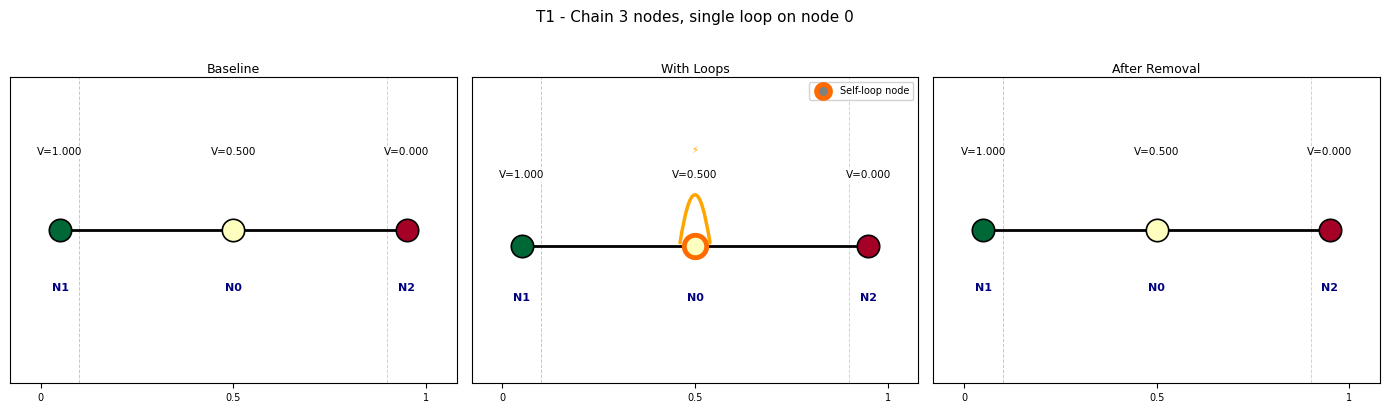

    plot -> /content/drive/MyDrive/ColabProject/experiments/exp_658/voltage_profiles.png


In [5]:
R_T1 = run_self_loop_test(intersections_t1, graph_t1, seg_t1, src_t1, drn_t1,
                          k_test, [0], label='T1')
assert abs(R_T1["looped"]["impedance"] - R_T1["baseline"]["impedance"]) < 1e-3
assert abs(R_T1["cleaned"]["impedance"] - R_T1["baseline"]["impedance"]) < 1e-6
assert check_percolation(R_T1["looped"]["seg"], src_t1, drn_t1) == True

em = setup_experiment()
save_self_loop_experiment(em=em, k=k_test,
    title='T1 - Chain 3 nodes, single loop on internal node (0)',
    intersections=intersections_t1, graph=graph_t1,
    seg_baseline=seg_t1, seg_with_loops=R_T1["looped"]["seg"],
    seg_cleaned=R_T1["cleaned"]["seg"],
    res_baseline=R_T1["baseline"]["result"],
    res_with_loops=R_T1["looped"]["result"],
    res_cleaned=R_T1["cleaned"]["result"],
    loop_description='1 loop on internal node 0',
    src_node=src_t1, drn_node=drn_t1)
display_and_save_plot(em.experiment_dir, intersections_t1,
    seg_t1, R_T1["looped"]["seg"], R_T1["cleaned"]["seg"],
    R_T1["baseline"]["result"], R_T1["looped"]["result"], R_T1["cleaned"]["result"],
    src_t1, drn_t1, topology='chain',
    title='T1 - Chain 3 nodes, single loop on node 0')

---
## T2 — Chain (3 nodes): Self-loops on source (1) and drain (2)

- **Network:** Chain‑3
- **loop_nodes = [1, 2]** → one self-loop each on source node 1 and drain node 2
- Self-loops on boundary nodes should not affect connectivity or impedance.

  [T2 baseline]
    Nodes: 3,  Edges: 2  (self-loops: 0)
    Source node: 1  (x=0.050)
    Drain  node: 2  (x=0.950)
    Percolation: YES
    Condition number of M: 1.000e+00    Singular: no
    Impedance R = 2000.000000 Ohm
  [T2 looped]
    Nodes: 3,  Edges: 4  (self-loops: 2)
    Source node: 1  (x=0.050)
    Drain  node: 2  (x=0.950)
    Percolation: YES
    Condition number of M: 1.000e+00    Singular: no
    Impedance R = 2000.000000 Ohm
  [T2 cleaned]
    Nodes: 3,  Edges: 2  (self-loops: 0)
    Source node: 1  (x=0.050)
    Drain  node: 2  (x=0.950)
    Percolation: YES
    Condition number of M: 1.000e+00    Singular: no
    Impedance R = 2000.000000 Ohm
EXPERIMENT CONFIGURATION
  Environment: Google Colab
  Experiment #: 659
  Timestamp: 20260616_150039
  Results directory: /content/drive/MyDrive/ColabProject/experiments/exp_659

  [OK] JSON saved: laplacian_info.json
  [OK] JSON saved: experiment_summary.json
  [WARNING] PDF auto-generation failed: No module named 'reportlab

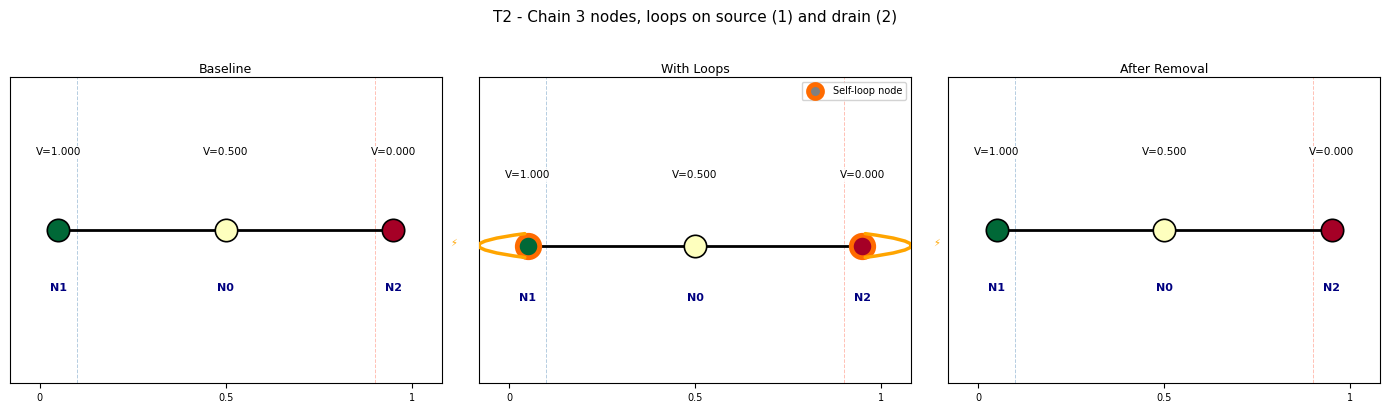

    plot -> /content/drive/MyDrive/ColabProject/experiments/exp_659/voltage_profiles.png


In [6]:
R_T2 = run_self_loop_test(intersections_t1, graph_t1, seg_t1, src_t1, drn_t1,
                          k_test, [1, 2], label='T2')
assert abs(R_T2["looped"]["impedance"] - R_T2["baseline"]["impedance"]) < 1e-3
assert abs(R_T2["cleaned"]["impedance"] - R_T2["baseline"]["impedance"]) < 1e-6
assert check_percolation(R_T2["looped"]["seg"], src_t1, drn_t1) == True

em = setup_experiment()
save_self_loop_experiment(em=em, k=k_test,
    title='T2 - Chain 3 nodes, loops on source (1) and drain (2)',
    intersections=intersections_t1, graph=graph_t1,
    seg_baseline=seg_t1, seg_with_loops=R_T2["looped"]["seg"],
    seg_cleaned=R_T2["cleaned"]["seg"],
    res_baseline=R_T2["baseline"]["result"],
    res_with_loops=R_T2["looped"]["result"],
    res_cleaned=R_T2["cleaned"]["result"],
    loop_description='1 loop on source (1) + 1 on drain (2)',
    src_node=src_t1, drn_node=drn_t1)
display_and_save_plot(em.experiment_dir, intersections_t1,
    seg_t1, R_T2["looped"]["seg"], R_T2["cleaned"]["seg"],
    R_T2["baseline"]["result"], R_T2["looped"]["result"], R_T2["cleaned"]["result"],
    src_t1, drn_t1, topology='chain',
    title='T2 - Chain 3 nodes, loops on source (1) and drain (2)')

---
## T3 — Chain (3 nodes): Two self-loops on the same internal node 0

- **Network:** Chain‑3
- **loop_nodes = [0, 0]** → two self-loops stacked on node 0
- Multiple loops on a single node should still leave impedance unchanged.

  [T3 baseline]
    Nodes: 3,  Edges: 2  (self-loops: 0)
    Source node: 1  (x=0.050)
    Drain  node: 2  (x=0.950)
    Percolation: YES
    Condition number of M: 1.000e+00    Singular: no
    Impedance R = 2000.000000 Ohm
  [T3 looped]
    Nodes: 3,  Edges: 4  (self-loops: 2)
    Source node: 1  (x=0.050)
    Drain  node: 2  (x=0.950)
    Percolation: YES
    Condition number of M: 1.000e+00    Singular: no
    Impedance R = 2000.000000 Ohm
  [T3 cleaned]
    Nodes: 3,  Edges: 2  (self-loops: 0)
    Source node: 1  (x=0.050)
    Drain  node: 2  (x=0.950)
    Percolation: YES
    Condition number of M: 1.000e+00    Singular: no
    Impedance R = 2000.000000 Ohm
EXPERIMENT CONFIGURATION
  Environment: Google Colab
  Experiment #: 660
  Timestamp: 20260616_150040
  Results directory: /content/drive/MyDrive/ColabProject/experiments/exp_660

  [OK] JSON saved: laplacian_info.json
  [OK] JSON saved: experiment_summary.json
  [WARNING] PDF auto-generation failed: No module named 'reportlab

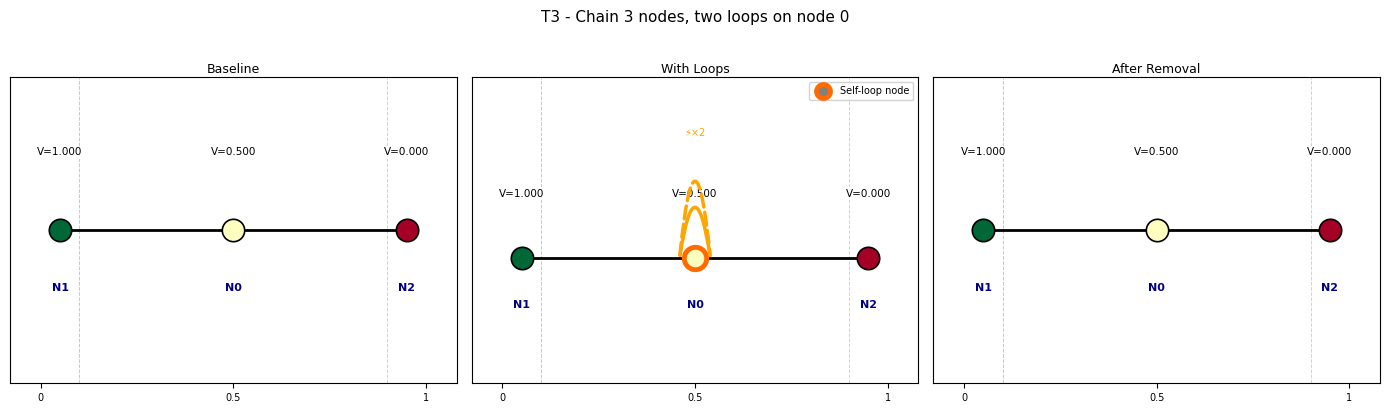

    plot -> /content/drive/MyDrive/ColabProject/experiments/exp_660/voltage_profiles.png


In [7]:
R_T3 = run_self_loop_test(intersections_t1, graph_t1, seg_t1, src_t1, drn_t1,
                          k_test, [0, 0], label='T3')
assert abs(R_T3["looped"]["impedance"] - R_T3["baseline"]["impedance"]) < 1e-3
assert abs(R_T3["cleaned"]["impedance"] - R_T3["baseline"]["impedance"]) < 1e-6
assert check_percolation(R_T3["looped"]["seg"], src_t1, drn_t1) == True

em = setup_experiment()
save_self_loop_experiment(em=em, k=k_test,
    title='T3 - Chain 3 nodes, two loops on internal node 0',
    intersections=intersections_t1, graph=graph_t1,
    seg_baseline=seg_t1, seg_with_loops=R_T3["looped"]["seg"],
    seg_cleaned=R_T3["cleaned"]["seg"],
    res_baseline=R_T3["baseline"]["result"],
    res_with_loops=R_T3["looped"]["result"],
    res_cleaned=R_T3["cleaned"]["result"],
    loop_description='2 loops on internal node 0',
    src_node=src_t1, drn_node=drn_t1)
display_and_save_plot(em.experiment_dir, intersections_t1,
    seg_t1, R_T3["looped"]["seg"], R_T3["cleaned"]["seg"],
    R_T3["baseline"]["result"], R_T3["looped"]["result"], R_T3["cleaned"]["result"],
    src_t1, drn_t1, topology='chain',
    title='T3 - Chain 3 nodes, two loops on node 0')

---
## T4 — Ladder (4 nodes): One self-loop on node 0, one on node 1

- **Network:** Ladder‑4
- **loop_nodes = [0, 1]** → one self-loop each on I1 (node 0) and I2 (node 1)
- Both internal nodes of the ladder carry a loop.

  [T4 baseline]
    Nodes: 4,  Edges: 5  (self-loops: 0)
    Source node: 2  (x=0.050)
    Drain  node: 3  (x=0.950)
    Percolation: YES
    Condition number of M: 2.000e+00    Singular: no
    Impedance R = 1000.000000 Ohm
  [T4 looped]
    Nodes: 4,  Edges: 7  (self-loops: 2)
    Source node: 2  (x=0.050)
    Drain  node: 3  (x=0.950)
    Percolation: YES
    Condition number of M: 2.000e+00    Singular: no
    Impedance R = 1000.000000 Ohm
  [T4 cleaned]
    Nodes: 4,  Edges: 5  (self-loops: 0)
    Source node: 2  (x=0.050)
    Drain  node: 3  (x=0.950)
    Percolation: YES
    Condition number of M: 2.000e+00    Singular: no
    Impedance R = 1000.000000 Ohm
EXPERIMENT CONFIGURATION
  Environment: Google Colab
  Experiment #: 661
  Timestamp: 20260616_150041
  Results directory: /content/drive/MyDrive/ColabProject/experiments/exp_661

  [OK] JSON saved: laplacian_info.json
  [OK] JSON saved: experiment_summary.json
  [WARNING] PDF auto-generation failed: No module named 'reportlab

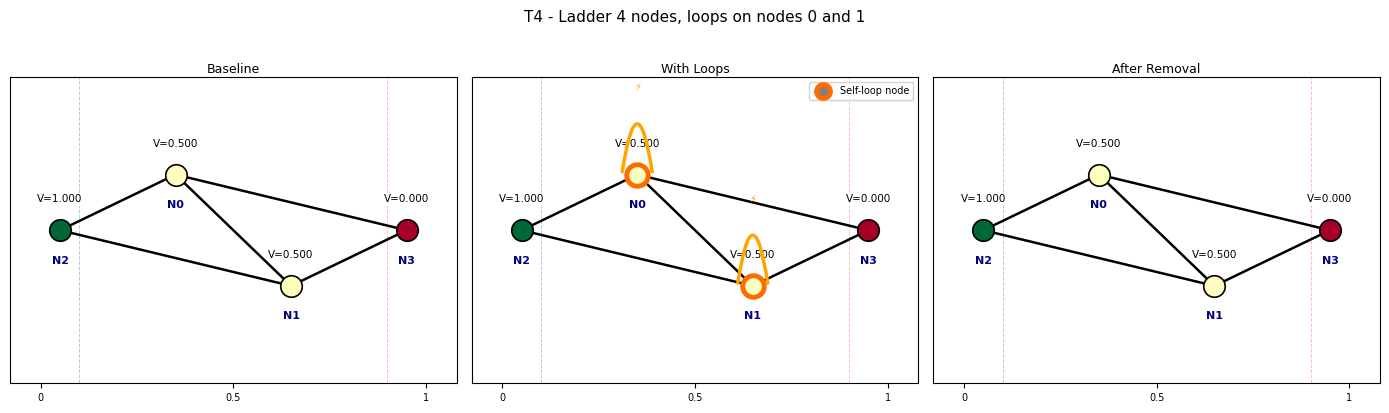

    plot -> /content/drive/MyDrive/ColabProject/experiments/exp_661/voltage_profiles.png


In [8]:
R_T4 = run_self_loop_test(intersections_t2, graph_t2, seg_t2, src_t2, drn_t2,
                          k_test, [0, 1], label='T4')
assert abs(R_T4["looped"]["impedance"] - R_T4["baseline"]["impedance"]) < 1e-3
assert abs(R_T4["cleaned"]["impedance"] - R_T4["baseline"]["impedance"]) < 1e-6
assert check_percolation(R_T4["looped"]["seg"], src_t2, drn_t2) == True

em = setup_experiment()
save_self_loop_experiment(em=em, k=k_test,
    title='T4 - Ladder 4 nodes, one loop on node 0 + one on node 1',
    intersections=intersections_t2, graph=graph_t2,
    seg_baseline=seg_t2, seg_with_loops=R_T4["looped"]["seg"],
    seg_cleaned=R_T4["cleaned"]["seg"],
    res_baseline=R_T4["baseline"]["result"],
    res_with_loops=R_T4["looped"]["result"],
    res_cleaned=R_T4["cleaned"]["result"],
    loop_description='1 loop on I1 (node 0) + 1 on I2 (node 1)',
    src_node=src_t2, drn_node=drn_t2)
display_and_save_plot(em.experiment_dir, intersections_t2,
    seg_t2, R_T4["looped"]["seg"], R_T4["cleaned"]["seg"],
    R_T4["baseline"]["result"], R_T4["looped"]["result"], R_T4["cleaned"]["result"],
    src_t2, drn_t2, topology='ladder',
    title='T4 - Ladder 4 nodes, loops on nodes 0 and 1')

---
## T5 — Ladder (4 nodes): Three self-loops on node 0, one on node 1

- **Network:** Ladder‑4
- **loop_nodes = [0, 0, 0, 1]** → three loops on I1 (node 0), one on I2 (node 1)
- Tests uneven loop distribution across nodes.

  [T5 baseline]
    Nodes: 4,  Edges: 5  (self-loops: 0)
    Source node: 2  (x=0.050)
    Drain  node: 3  (x=0.950)
    Percolation: YES
    Condition number of M: 2.000e+00    Singular: no
    Impedance R = 1000.000000 Ohm
  [T5 looped]
    Nodes: 4,  Edges: 9  (self-loops: 4)
    Source node: 2  (x=0.050)
    Drain  node: 3  (x=0.950)
    Percolation: YES
    Condition number of M: 2.000e+00    Singular: no
    Impedance R = 1000.000000 Ohm
  [T5 cleaned]
    Nodes: 4,  Edges: 5  (self-loops: 0)
    Source node: 2  (x=0.050)
    Drain  node: 3  (x=0.950)
    Percolation: YES
    Condition number of M: 2.000e+00    Singular: no
    Impedance R = 1000.000000 Ohm
EXPERIMENT CONFIGURATION
  Environment: Google Colab
  Experiment #: 662
  Timestamp: 20260616_150042
  Results directory: /content/drive/MyDrive/ColabProject/experiments/exp_662

  [OK] JSON saved: laplacian_info.json
  [OK] JSON saved: experiment_summary.json
  [WARNING] PDF auto-generation failed: No module named 'reportlab

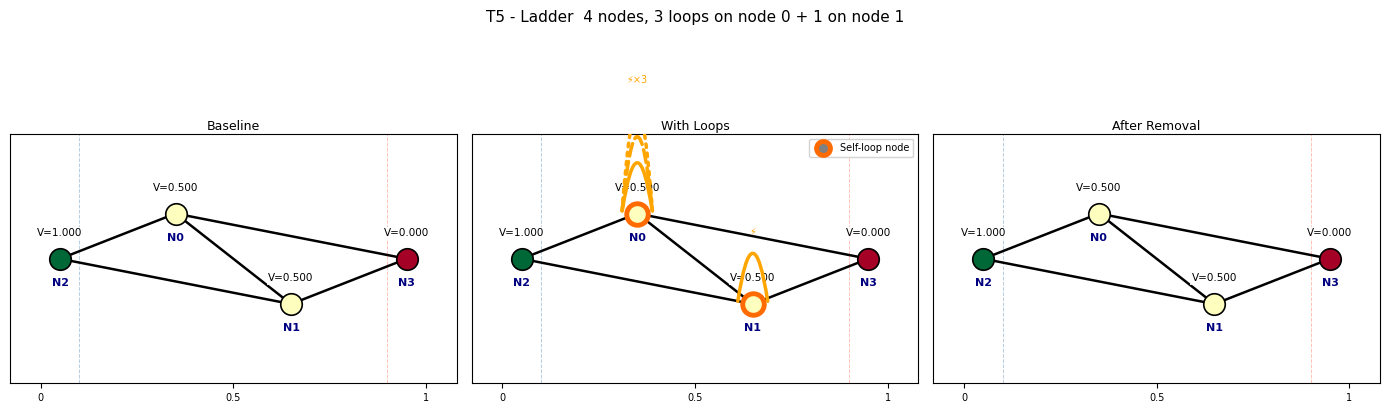

    plot -> /content/drive/MyDrive/ColabProject/experiments/exp_662/voltage_profiles.png


In [9]:
R_T5 = run_self_loop_test(intersections_t2, graph_t2, seg_t2, src_t2, drn_t2,
                          k_test, [0, 0, 0, 1], label='T5')
assert abs(R_T5["looped"]["impedance"] - R_T5["baseline"]["impedance"]) < 1e-3
assert abs(R_T5["cleaned"]["impedance"] - R_T5["baseline"]["impedance"]) < 1e-6
assert check_percolation(R_T5["looped"]["seg"], src_t2, drn_t2) == True

em = setup_experiment()
save_self_loop_experiment(em=em, k=k_test,
    title='T5 - Ladder 4 nodes, 3 loops on node 0 + 1 on node 1',
    intersections=intersections_t2, graph=graph_t2,
    seg_baseline=seg_t2, seg_with_loops=R_T5["looped"]["seg"],
    seg_cleaned=R_T5["cleaned"]["seg"],
    res_baseline=R_T5["baseline"]["result"],
    res_with_loops=R_T5["looped"]["result"],
    res_cleaned=R_T5["cleaned"]["result"],
    loop_description='3 loops on I1 (node 0) + 1 on I2 (node 1)',
    src_node=src_t2, drn_node=drn_t2)
display_and_save_plot(em.experiment_dir, intersections_t2,
    seg_t2, R_T5["looped"]["seg"], R_T5["cleaned"]["seg"],
    R_T5["baseline"]["result"], R_T5["looped"]["result"], R_T5["cleaned"]["result"],
    src_t2, drn_t2, topology='ladder',
    title='T5 - Ladder  4 nodes, 3 loops on node 0 + 1 on node 1')

---
## T6 — Chain (5 nodes): Self-loops on nodes 1, 2, and 3

- **Network:** Chain‑5
- **loop_nodes = [1, 2, 3]** → one self-loop each on internal nodes I1, I2, I3
- Tests multiple internal nodes with loops on a longer chain.

  [T6 baseline]
    Nodes: 5,  Edges: 4  (self-loops: 0)
    Source node: 3  (x=0.050)
    Drain  node: 4  (x=0.950)
    Percolation: YES
    Condition number of M: 5.828e+00    Singular: no
    Impedance R = 4000.000000 Ohm
  [T6 looped]
    Nodes: 5,  Edges: 7  (self-loops: 3)
    Source node: 3  (x=0.050)
    Drain  node: 4  (x=0.950)
    Percolation: YES
    Condition number of M: 5.828e+00    Singular: no
    Impedance R = 4000.000000 Ohm
  [T6 cleaned]
    Nodes: 5,  Edges: 4  (self-loops: 0)
    Source node: 3  (x=0.050)
    Drain  node: 4  (x=0.950)
    Percolation: YES
    Condition number of M: 5.828e+00    Singular: no
    Impedance R = 4000.000000 Ohm
EXPERIMENT CONFIGURATION
  Environment: Google Colab
  Experiment #: 663
  Timestamp: 20260616_150043
  Results directory: /content/drive/MyDrive/ColabProject/experiments/exp_663

  [OK] JSON saved: laplacian_info.json
  [OK] JSON saved: experiment_summary.json
  [WARNING] PDF auto-generation failed: No module named 'reportlab

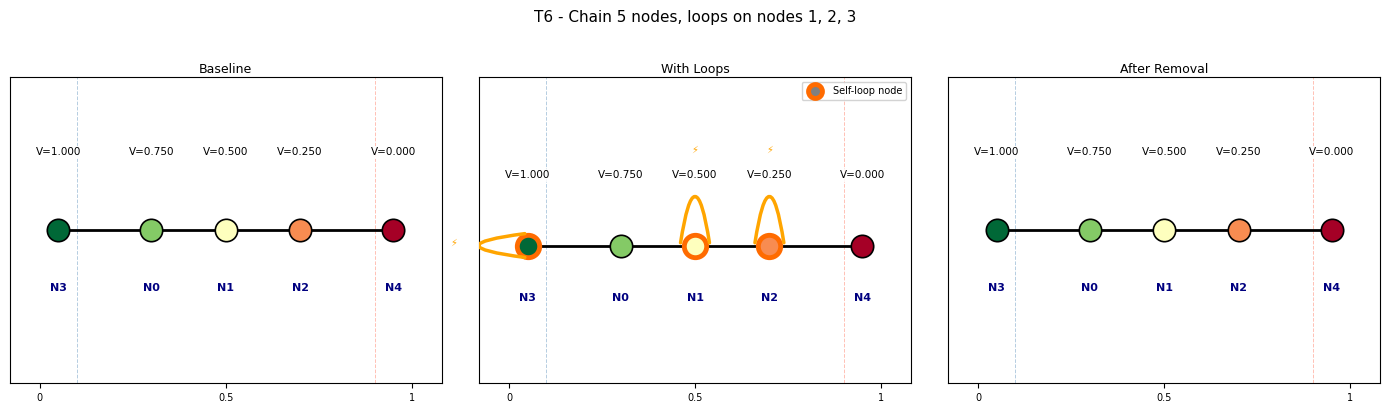

    plot -> /content/drive/MyDrive/ColabProject/experiments/exp_663/voltage_profiles.png


In [10]:
R_T6 = run_self_loop_test(intersections_t7, graph_t7, seg_t7, src_t7, drn_t7,
                          k_test, [1, 2, 3], label='T6')
assert abs(R_T6["looped"]["impedance"] - R_T6["baseline"]["impedance"]) < 1e-3
assert abs(R_T6["cleaned"]["impedance"] - R_T6["baseline"]["impedance"]) < 1e-6
assert check_percolation(R_T6["looped"]["seg"], src_t7, drn_t7) == True

em = setup_experiment()
save_self_loop_experiment(em=em, k=k_test,
    title='T6 - Chain 5 nodes, loops on nodes 1, 2, 3',
    intersections=intersections_t7, graph=graph_t7,
    seg_baseline=seg_t7, seg_with_loops=R_T6["looped"]["seg"],
    seg_cleaned=R_T6["cleaned"]["seg"],
    res_baseline=R_T6["baseline"]["result"],
    res_with_loops=R_T6["looped"]["result"],
    res_cleaned=R_T6["cleaned"]["result"],
    loop_description='1 loop each on nodes 1, 2, 3',
    src_node=src_t7, drn_node=drn_t7)
display_and_save_plot(em.experiment_dir, intersections_t7,
    seg_t7, R_T6["looped"]["seg"], R_T6["cleaned"]["seg"],
    R_T6["baseline"]["result"], R_T6["looped"]["result"], R_T6["cleaned"]["result"],
    src_t7, drn_t7, topology='chain',
    title='T6 - Chain 5 nodes, loops on nodes 1, 2, 3')